# Simulação

Observe 2 s a 500 Hz (Δf = 0,5 Hz), compare a aquisição a 100 Hz e estude um registro de 0,73 s para provocar vazamento. O modelo do sensor é um passa-baixas de primeira ordem com τ = 20 ms.

Execute as células em ordem. Os dados são sintéticos; não representam medições experimentais.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import pandas as pd
from IPython.display import display
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True})

def espectro(x, fs, janela=None, nfft=None):
    w = np.ones(len(x)) if janela is None else janela
    X = np.fft.rfft(x*w, n=nfft)
    f = np.fft.rfftfreq(len(x) if nfft is None else nfft, 1/fs)
    A = np.abs(X)/w.sum()
    A[1:] *= 2
    if (len(x) if nfft is None else nfft) % 2 == 0:
        A[-1] /= 2
    return f, A

def plano(b, a, ax):
    # Coeficientes em potências de z^-1; completar graus para exibir polos na origem.
    grau = max(len(b), len(a))-1
    z = np.roots(np.pad(b, (0, grau+1-len(b))))
    p = np.roots(np.pad(a, (0, grau+1-len(a))))
    theta = np.linspace(0, 2*np.pi, 500)
    ax.plot(np.cos(theta), np.sin(theta), 'k--', label='Círculo unitário')
    ax.scatter(z.real, z.imag, facecolors='none', edgecolors='C0', label='Zeros')
    ax.scatter(p.real, p.imag, marker='x', color='C1', label='Polos')
    ax.set(xlabel='Parte real', ylabel='Parte imaginária', title='Plano z')
    ax.axis('equal'); ax.legend()

def analisar(b, a=(1,), fs=1000, nome='Filtro'):
    w, H = signal.freqz(b, a, worN=4096, fs=fs)
    impulso = np.r_[1., np.zeros(119)]
    h = signal.lfilter(b, a, impulso)
    fig, ax = plt.subplots(2, 3, figsize=(14, 7))
    ax[0,0].stem(np.arange(len(h)), h); ax[0,0].set(title=nome+' — impulso', xlabel='n (amostras)', ylabel='h[n]')
    plano(np.asarray(b), np.asarray(a), ax[0,1])
    ax[0,2].plot(w, np.abs(H)); ax[0,2].set(title='Magnitude linear', xlabel='f (Hz)', ylabel='Ganho')
    ax[1,0].plot(w, 20*np.log10(np.maximum(np.abs(H), 1e-12))); ax[1,0].set(title='Magnitude em dB', xlabel='f (Hz)', ylabel='Ganho (dB)', ylim=(-100,5))
    fase = np.unwrap(np.angle(H))
    ax[1,1].plot(w, fase); ax[1,1].set(title='Fase', xlabel='f (Hz)', ylabel='Fase (rad)')
    gd = -np.gradient(fase, 2*np.pi*w/fs)
    gd[np.abs(H)<1e-5] = np.nan
    ax[1,2].plot(w, gd); ax[1,2].set(title='Atraso de grupo (fora dos nulos)', xlabel='f (Hz)', ylabel='Amostras')
    fig.tight_layout(); plt.show()
    print('b =', np.asarray(b)); print('a =', np.asarray(a))
    print('Polos:', np.roots(a), 'Estável causal:', np.all(np.abs(np.roots(a)) < 1))


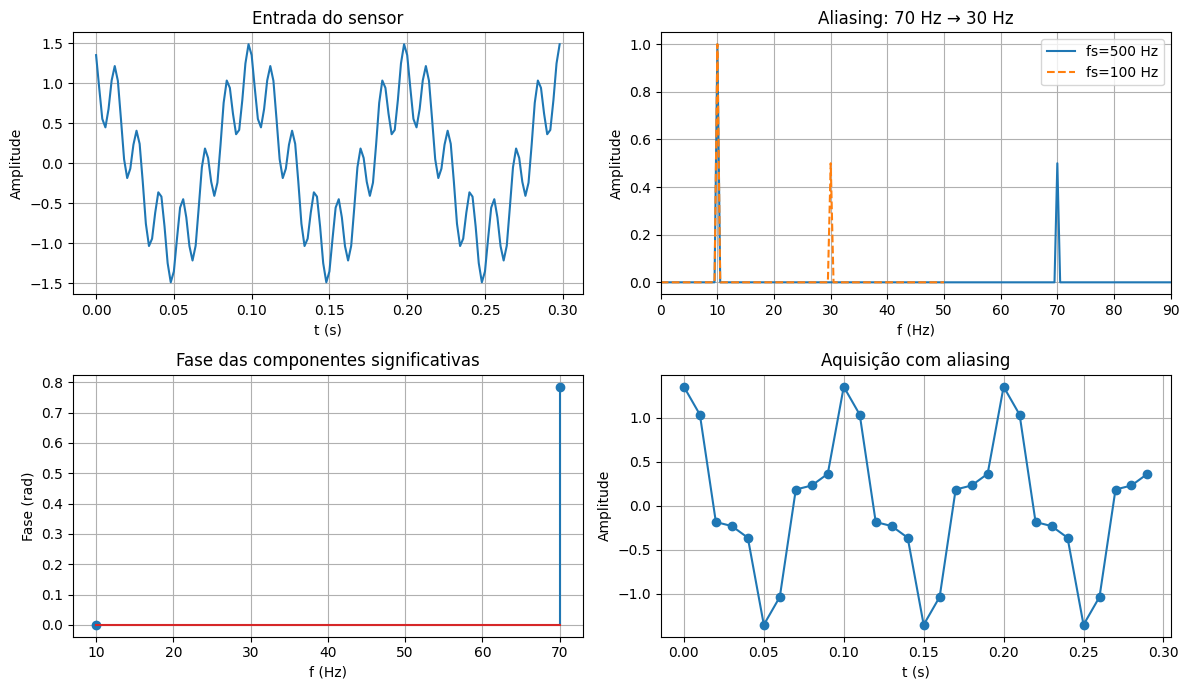

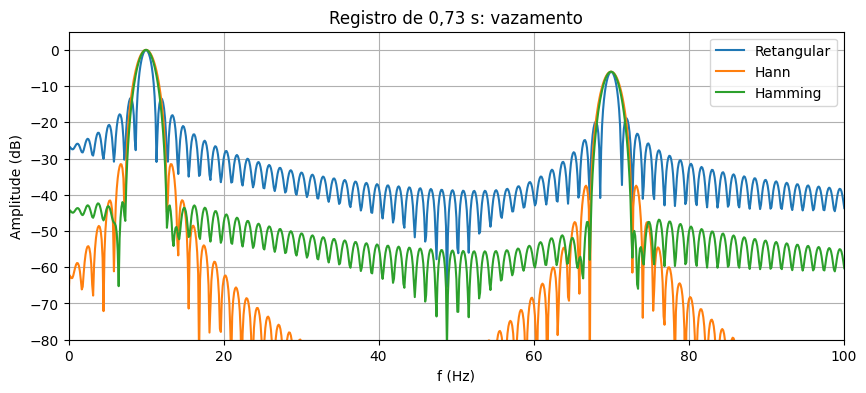

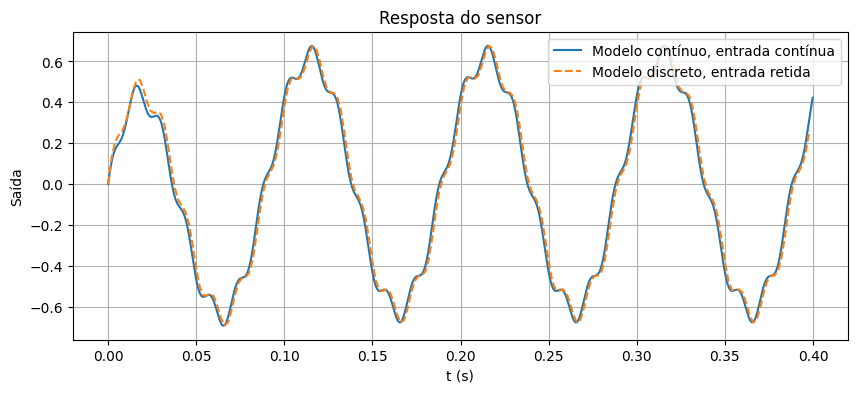

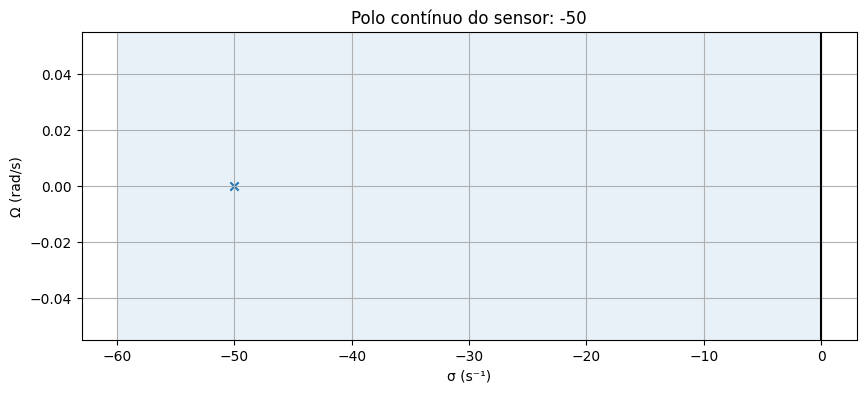

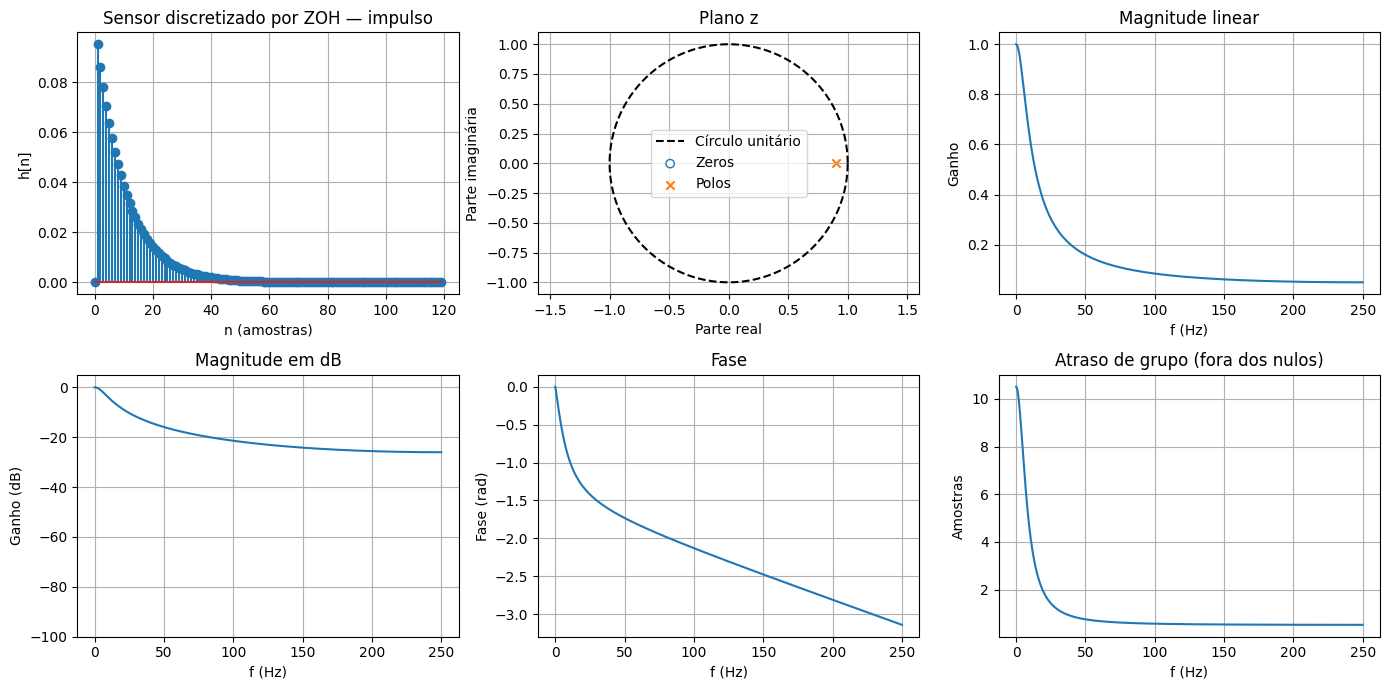

b = [0.         0.09516258]
a = [ 1.         -0.90483742]
Polos: [0.90483742] Estável causal: True
fs=500 Hz > 2×70 Hz; Δf=0,5 Hz; polo z = 0.9048374180359595
Picos identificados: [70. 10.] Hz
10 Hz: ganho contínuo = 0.6226769922994999
70 Hz: ganho contínuo = 0.11295455441066325


In [2]:
fs=500; t=np.arange(1000)/fs
x=np.cos(2*np.pi*10*t)+.5*np.cos(2*np.pi*70*t+np.pi/4)
fig,ax=plt.subplots(2,2,figsize=(12,7))
ax[0,0].plot(t[:150],x[:150]); ax[0,0].set(title='Entrada do sensor',xlabel='t (s)',ylabel='Amplitude')
f,A=espectro(x,fs); ax[0,1].plot(f,A,label='fs=500 Hz')
X=np.fft.rfft(x); mask=np.abs(X)>1e-7
ax[1,0].stem(f[mask],np.angle(X[mask])); ax[1,0].set(title='Fase das componentes significativas',xlabel='f (Hz)',ylabel='Fase (rad)')
ta=np.arange(200)/100; xa=np.cos(2*np.pi*10*ta)+.5*np.cos(2*np.pi*70*ta+np.pi/4)
fa,Aa=espectro(xa,100); ax[0,1].plot(fa,Aa,'--',label='fs=100 Hz'); ax[0,1].set(xlim=(0,90),title='Aliasing: 70 Hz → 30 Hz',xlabel='f (Hz)',ylabel='Amplitude'); ax[0,1].legend()
ax[1,1].plot(ta[:30],xa[:30],'o-'); ax[1,1].set(title='Aquisição com aliasing',xlabel='t (s)',ylabel='Amplitude')
plt.tight_layout(); plt.show()
N=365; xn=x[:N]
for nome,w in [('Retangular',np.ones(N)),('Hann',signal.windows.hann(N,sym=False)),('Hamming',signal.windows.hamming(N,sym=False))]:
    fw,Aw=espectro(xn,fs,w,4096); plt.plot(fw,20*np.log10(np.maximum(Aw,1e-8)),label=nome)
plt.xlim(0,100); plt.ylim(-80,5); plt.xlabel('f (Hz)'); plt.ylabel('Amplitude (dB)'); plt.title('Registro de 0,73 s: vazamento'); plt.legend(); plt.show()
tc=np.linspace(0,2,10001); xc=np.cos(2*np.pi*10*tc)+.5*np.cos(2*np.pi*70*tc+np.pi/4)
_,yc,_=signal.lsim(([1],[.02,1]),U=xc,T=tc)
b,a,dt=signal.cont2discrete(([1],[.02,1]),1/fs,method='zoh'); b=b.ravel()
p=np.exp(-50/fs)
assert np.allclose(np.roots(a),[p])
y=signal.lfilter(b,a,x)
plt.plot(tc[:2000],yc[:2000],label='Modelo contínuo, entrada contínua'); plt.plot(t[:200],y[:200],'--',label='Modelo discreto, entrada retida')
plt.xlabel('t (s)'); plt.ylabel('Saída'); plt.title('Resposta do sensor'); plt.legend(); plt.show()
plt.scatter(-50,0,marker='x'); plt.axvline(0,color='k'); plt.axvspan(-60,0,alpha=.1); plt.xlabel('σ (s⁻¹)'); plt.ylabel('Ω (rad/s)'); plt.title('Polo contínuo do sensor: -50'); plt.show()
analisar(b,a,fs,'Sensor discretizado por ZOH')
print('fs=500 Hz > 2×70 Hz; Δf=0,5 Hz; polo z =',p)
print('Picos identificados:',f[np.argsort(A)[-2:]],'Hz')
for fi in [10,70]:
    ganho=1/np.sqrt(1+(2*np.pi*fi*.02)**2)
    print(fi,'Hz: ganho contínuo =',ganho)
